*** AERMOD SAMPLE DATA ANALYSIS ***

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

output_path = Path("SampleRun/AERMOD/aermod.out")
print("File exists: ", output_path.exists())

with open(output_path, 'r') as f:
    lines = f.readlines()

print(len(lines))

File exists:  True
1630


heh

In [3]:
for i, line in enumerate(lines):
    if "THE PERIOD" in line and "AVERAGE CONCENTRATION" in line:
        start = i
        break

values = []
for line in lines[start:start + 25]:
    # print(line.rstrip())
    try:
        if line.strip() != '' :
            row = [float(x) for x in line.split()]
            if len(row) >= 3:
                values.append(row[0:3])
                
            if len(row) >= 6:
                values.append(row[3:])
    except ValueError:
        # print("Non-numerical row")
        continue

print(values)

[[495510.0, 513680.0, 6.08535], [493900.0, 513200.0, 8.32741], [492700.0, 513440.0, 8.50722], [492440.0, 511190.0, 5.07408], [495400.0, 515180.0, 6.64201], [495300.0, 513880.0, 6.50462], [496430.0, 514500.0, 5.57588]]


,x,y,concentration
0,495510.0,513680.0,6.08535
1,493900.0,513200.0,8.32741
2,492700.0,513440.0,8.50722
3,492440.0,511190.0,5.07408
4,495400.0,515180.0,6.64201
5,495300.0,513880.0,6.50462
6,496430.0,514500.0,5.57588


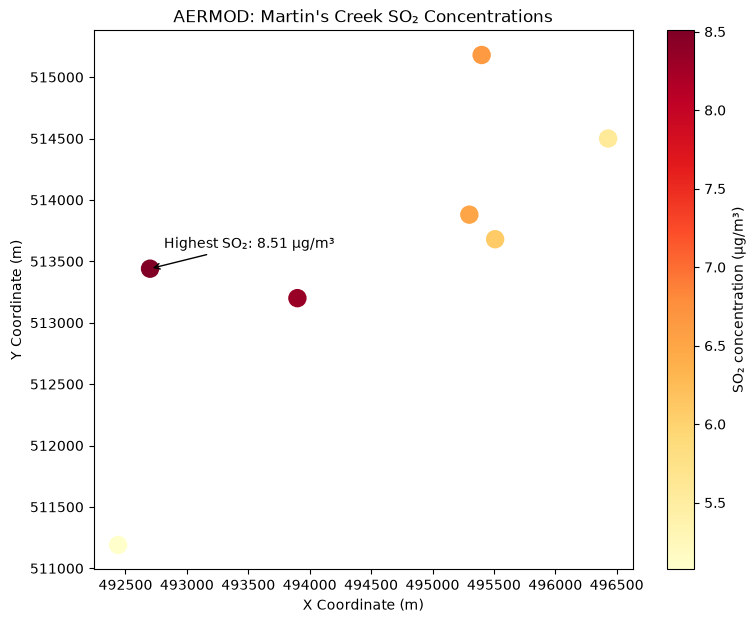

In [4]:
df = pd.DataFrame(
    values,
    columns=['x', 'y', 'concentration']
)

display(df)

# Plotting 
fig, ax = plt.subplots(figsize=(9, 7))

scatter = ax.scatter(
    df["x"],
    df["y"],
    c=df["concentration"],
    cmap="YlOrRd",
    s=150
)

fig.colorbar(
    scatter,
    ax=ax,
    label="SO₂ concentration (µg/m³)"
)

ax.set_xlabel("X Coordinate (m)")
ax.set_ylabel("Y Coordinate (m)")
ax.set_title("AERMOD: Martin's Creek SO₂ Concentrations")
ax.set_aspect("equal")


# Find highest concentration
h_concen = df['concentration'].idxmax()
h_receptor = df.iloc[h_concen]
x = h_receptor['x']
y = h_receptor['y']

ax.annotate(
    f"Highest SO₂: {h_receptor['concentration']:.2f} μg/m³",
    xy=(x, y),
    xytext=(10, 15),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"}
)

plt.show()

In [5]:
from pyproj import Transformer
# Let's convert x and y to actual coordinates
df["utm_x"] = df["x"]
df["utm_y"] = df["y"] + 4_000_000

transformer = Transformer.from_crs(
    "EPSG:32618",
    "EPSG:4326",
    always_xy=True
)

df["longitude"], df["latitude"] = transformer.transform(
    df["utm_x"].to_numpy(),
    df["utm_y"].to_numpy()
)

display(df)

,x,y,concentration,utm_x,utm_y,longitude,latitude
0,495510.0,513680.0,6.08535,495510.0,4513680.0,-75.053207,40.774083
1,493900.0,513200.0,8.32741,493900.0,4513200.0,-75.072280,40.769749
2,492700.0,513440.0,8.50722,492700.0,4513440.0,-75.086502,40.771901
3,492440.0,511190.0,5.07408,492440.0,4511190.0,-75.089556,40.751629
4,495400.0,515180.0,6.64201,495400.0,4515180.0,-75.054521,40.787595
5,495300.0,513880.0,6.50462,495300.0,4513880.0,-75.055697,40.775884
6,496430.0,514500.0,5.57588,496430.0,4514500.0,-75.042309,40.781475


In [6]:
import folium

m = folium.Map(
    location=[df["latitude"].mean(), df["longitude"].mean()],
    zoom_start=12
)

for _, row in df.iterrows():
    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=7,
        popup=f"SO₂: {row['concentration']:.2f} µg/m³",
        color="red",
        fill=True,
        fill_opacity=0.7
    ).add_to(m)

display(m)

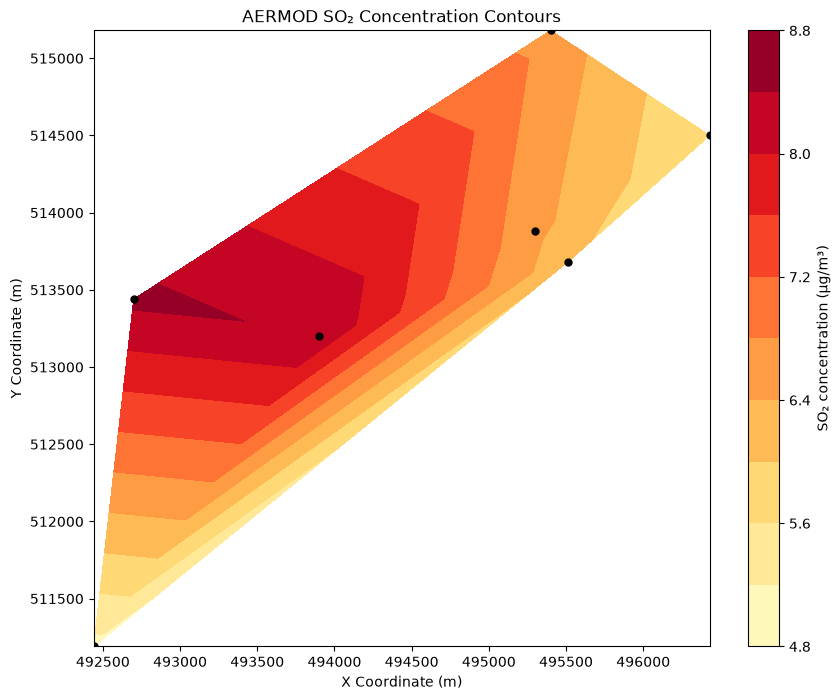

In [9]:
fig, ax = plt.subplots(figsize=(10, 8))
contours = ax.tricontourf(
    df['x'],
    df['y'],
    df['concentration'],
    levels=10,
    cmap="YlOrRd"
)

ax.scatter(
    df["x"],
    df["y"],
    color="black",
    s=25
)

fig.colorbar(
    contours,
    ax=ax,
    label="SO₂ concentration (µg/m³)"
)

ax.set_xlabel("X Coordinate (m)")
ax.set_ylabel("Y Coordinate (m)")
ax.set_title("AERMOD SO₂ Concentration Contours")
ax.set_aspect("equal")

plt.show()